# Mixed → Pair — Five-seed evaluation and error analysis

Read the **20 saved runs** (five seeds × four curricula) from the matched-exposure experiment. The notebook analyzes task accuracy, learning efficiency, predicted Yes/No bias, evaluation subgroups, forgetting, and recovery. It does not train models or generate synthetic example results.


In [ ]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_REL = Path("outputs/medium_world/dataset")
OUT_REL = Path("outputs/medium_world/experiments/mixed_pair_control/five_seeds")
DATA_DIR = PROJECT_ROOT / DATA_REL
RESULT_DIR = PROJECT_ROOT / OUT_REL
RESULTS_FILE = RESULT_DIR / "schedule_comparison.json"
TRACE_DIR = RESULT_DIR / "prediction_traces"
FINAL_CSV = RESULT_DIR / "final_by_seed.csv"
PAIRED_CSV = RESULT_DIR / "paired_differences.csv"
EXPOSURE_CSV = RESULT_DIR / "phase_exposure.csv"
SUBGROUP_CSV = RESULT_DIR / "prediction_error_subgroups.csv"
CHANGES_CSV = RESULT_DIR / "prediction_change_summary.csv"
EXAMPLE_CHANGES_CSV = RESULT_DIR / "prediction_changes_by_example.csv.gz"
CURVES_CSV = RESULT_DIR / "binding_learning_curves.csv"
FIGURE_FINAL = RESULT_DIR / "final_binding_id_ood.png"
FIGURE_CURVES = RESULT_DIR / "binding_learning_curves.png"
FIGURE_EXPOSURE = RESULT_DIR / "binding_vs_exposure.png"
FIGURE_CLASS = RESULT_DIR / "binding_positive_recall_specificity.png"

In [ ]:
import json, math, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.medium_visual_world.learning import TASKS
from src.medium_visual_world.order_control import SCHEDULES
from src.medium_visual_world.prediction_tracking import (
    load_trace, compare_two, compare_three, summarize_changes
)

report = json.loads(RESULTS_FILE.read_text(encoding="utf-8"))
runs = sorted([r for r in report["runs"] if r["status"] == "completed"],
              key=lambda x: (x["seed"], x["schedule"]))
hashes = {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
          for name in ("train.jsonl", "id_dev.jsonl", "ood_dev.jsonl")}
assert report["dataset_hashes"] == hashes, "Dataset differs from training"
assert not any((r["steps_run"] != 9000 or r["schedule"] not in SCHEDULES)
               for r in runs)
assert len({(r["seed"],r["schedule"]) for r in runs}) == len(runs)
expected_seeds = [42, 43, 44, 45, 46]
assert set((r["seed"], r["schedule"]) for r in runs) == {
    (seed, schedule) for seed in expected_seeds for schedule in SCHEDULES
}, "Experiment has missing seed-schedule pairs"
traces = {}
for r in runs:
    path = RESULT_DIR / r["prediction_trace"]
    t = load_trace(path)
    assert t["metadata"]["seed"] == r["seed"]
    assert t["metadata"]["schedule"] == r["schedule"]
    for split in ("id_dev", "ood_dev"):
        b = t["splits"][split]
        assert np.array_equal(b["steps"], np.arange(0,9001,100))
        assert len(set(b["ids"])) == len(b["ids"])
    traces[(r["seed"],r["schedule"])] = t
print("Matched real prediction traces:",len(traces),"/",len(runs))

Matched real prediction traces: 20 / 20


## Fixed-final performance and paired comparisons

In [3]:
final_rows = []
for r in runs:
    f = r["final"]
    id_pair = f["id_dev"]["binary_by_template"]["pair"]
    ood_pair = f["ood_dev"]["binary_by_template"]["pair"]
    final_rows.append({"seed":r["seed"],"schedule":r["schedule"],
                       "id_pair":100*f["id_dev"]["by_template"]["pair"],
                       "ood_pair":100*f["ood_dev"]["by_template"]["pair"],
                       "pair_aulc":100*r["id_pair_aulc"],
                       "id_bce":f["id_dev"]["loss_by_template"]["pair"],
                       "ood_bce":f["ood_dev"]["loss"],
                       "id_tpr":100*id_pair["positive_recall"],
                       "id_tnr":100*id_pair["negative_specificity"],
                       "ood_tpr":100*ood_pair["positive_recall"],
                       "ood_tnr":100*ood_pair["negative_specificity"]})
final = pd.DataFrame(final_rows).sort_values(["seed","schedule"])
final.to_csv(FINAL_CSV,index=False)
display(final.round(2))
display(final.groupby("schedule").mean(numeric_only=True).drop(columns="seed").round(2))

,seed,schedule,id_pair,ood_pair,pair_aulc,id_bce,ood_bce,id_tpr,id_tnr,ood_tpr,ood_tnr
0,42,mixed,65.62,61.25,58.39,0.60,0.64,79.69,51.56,86.5,36.0
1,42,mixed_pair_focus,64.45,60.75,57.16,0.59,0.65,72.66,56.25,82.5,39.0
2,42,prereq_mixed_pair_focus,64.45,60.00,55.74,0.62,0.68,73.44,55.47,81.0,39.0
3,42,staged_pair_focus,65.23,55.75,55.27,0.60,0.82,68.75,61.72,69.5,42.0
4,43,mixed,58.59,54.25,55.89,0.63,0.69,69.53,47.66,51.5,57.0
5,43,mixed_pair_focus,60.55,55.50,55.18,0.66,0.70,70.31,50.78,72.5,38.5
6,43,prereq_mixed_pair_focus,60.94,53.50,54.83,0.64,0.71,63.28,58.59,49.5,57.5
7,43,staged_pair_focus,57.03,52.75,53.41,0.68,0.73,57.81,56.25,56.5,49.0
8,44,mixed,58.20,54.50,53.79,0.69,0.94,86.72,29.69,86.0,23.0
9,44,mixed_pair_focus,63.67,60.00,56.09,0.65,0.90,87.50,39.84,88.5,31.5


,id_pair,ood_pair,pair_aulc,id_bce,ood_bce,id_tpr,id_tnr,ood_tpr,ood_tnr
schedule,,,,,,,,,
mixed,61.33,56.6,56.79,0.63,0.76,75.94,46.72,77.2,36.0
mixed_pair_focus,62.89,57.0,56.06,0.64,0.75,75.78,50.00,75.7,38.3
prereq_mixed_pair_focus,62.89,57.0,54.93,0.65,0.76,74.06,51.72,66.4,47.6
staged_pair_focus,62.19,55.9,54.55,0.64,0.79,69.53,54.84,59.7,52.1


In [ ]:
COMPARISONS = [("staged_pair_focus","prereq_mixed_pair_focus"),
               ("staged_pair_focus","mixed_pair_focus"),
               ("mixed_pair_focus","mixed"),
               ("prereq_mixed_pair_focus","mixed_pair_focus")]
# Student t values for two-sided 95% intervals at n=2..5 paired seeds.
T_CRITICAL = {2:12.706,3:4.303,4:3.182,5:2.776}
paired_rows=[]
for a,b in COMPARISONS:
    left = final[final.schedule==a].set_index("seed")
    right = final[final.schedule==b].set_index("seed")
    for metric in ("id_pair","ood_pair","pair_aulc","id_tpr","id_tnr","ood_tpr","ood_tnr"):
        diff = (left[metric]-right[metric]).dropna()
        n = len(diff)
        mean=float(diff.mean())
        sd=float(diff.std(ddof=1)) if n>1 else float("nan")
        margin = T_CRITICAL[n]*sd/math.sqrt(n) if n in T_CRITICAL else float("nan")
        paired_rows.append({"comparison": f"{a} - {b}","metric":metric,
                            "n_seeds":n,"mean_difference_pp":mean,"sample_sd":sd,
                            "ci95_low":mean-margin,"ci95_high":mean+margin,
                            "positive_seeds":int((diff>0).sum()),
                            "seed_differences":json.dumps({str(k):round(v,4)
                                                            for k,v in diff.items()})})
paired=pd.DataFrame(paired_rows)
paired.to_csv(PAIRED_CSV,index=False)
display(paired[paired.metric.isin(["id_pair","ood_pair","pair_aulc"])].round(3))

,comparison,metric,n_seeds,mean_difference_pp,sample_sd,ci95_low,ci95_high,positive_seeds,seed_differences
0,staged_pair_focus - prereq_mixed_pair_focus,id_pair,5,-0.703,3.637,-5.219,3.812,3,"{""42"": 0.7812, ""43"": -3.9062, ""44"": 1.1719, ""4..."
1,staged_pair_focus - prereq_mixed_pair_focus,ood_pair,5,-1.100,2.133,-3.748,1.548,1,"{""42"": -4.25, ""43"": -0.75, ""44"": -1.25, ""45"": ..."
2,staged_pair_focus - prereq_mixed_pair_focus,pair_aulc,5,-0.377,1.069,-1.704,0.950,2,"{""42"": -0.4731, ""43"": -1.4193, ""44"": 1.0308, ""..."
7,staged_pair_focus - mixed_pair_focus,id_pair,5,-0.703,1.941,-3.113,1.707,3,"{""42"": 0.7812, ""43"": -3.5156, ""44"": 0.7812, ""4..."
8,staged_pair_focus - mixed_pair_focus,ood_pair,5,-1.100,4.895,-7.176,4.976,1,"{""42"": -5.0, ""43"": -2.75, ""44"": -4.5, ""45"": -0..."
9,staged_pair_focus - mixed_pair_focus,pair_aulc,5,-1.506,0.569,-2.213,-0.799,0,"{""42"": -1.888, ""43"": -1.773, ""44"": -1.7448, ""4..."
14,mixed_pair_focus - mixed,id_pair,5,1.562,2.471,-1.505,4.630,4,"{""42"": -1.1719, ""43"": 1.9531, ""44"": 5.4688, ""4..."
15,mixed_pair_focus - mixed,ood_pair,5,0.400,3.185,-3.554,4.354,2,"{""42"": -0.5, ""43"": 1.25, ""44"": 5.5, ""45"": -2.5..."
16,mixed_pair_focus - mixed,pair_aulc,5,-0.736,1.885,-3.076,1.604,1,"{""42"": -1.2261, ""43"": -0.7053, ""44"": 2.2917, ""..."
21,prereq_mixed_pair_focus - mixed_pair_focus,id_pair,5,0.000,2.227,-2.765,2.765,2,"{""42"": 0.0, ""43"": 0.3906, ""44"": -0.3906, ""45"":..."


## Exposure histories and learning curves

In [ ]:
exposure_rows,curve_rows=[] ,[]
for r in runs:
    for phase in r["phase_plan"]["phases"]:
        exposure_rows.append({"seed":r["seed"],"schedule":r["schedule"],
                              "phase":phase["name"],"total":phase["presentations"],
                              **{task:phase["by_template"].get(task,0) for task in TASKS}})
    for h in r["history"]:
        curve_rows.append({"seed":r["seed"],"schedule":r["schedule"],
                           "step":h["step"],"phase":h["phase"],
                           "pair_exposure":h["cumulative_task_presentations"].get("pair",0),
                           "id_pair":100*h["id_dev"]["by_template"]["pair"],
                           "ood_pair":100*h["ood_dev"]["by_template"]["pair"],
                           "id_shape":100*h["id_dev"]["by_template"]["shape"],
                           "id_conjunction":100*h["id_dev"]["by_template"]["conjunction"]})
exposure=pd.DataFrame(exposure_rows)
exposure.to_csv(EXPOSURE_CSV,index=False)
curves=pd.DataFrame(curve_rows)
curves.to_csv(CURVES_CSV,index=False)
display(exposure.groupby(["schedule","phase"])[list(TASKS)].mean().round(0))

color    shape  conjunction     pair
schedule                phase                                               
mixed                   common_mixed  22500.0  22500.0      22500.0  22500.0
                        mixed         90000.0  90000.0      90000.0  90000.0
mixed_pair_focus        common_mixed  22500.0  22500.0      22500.0  22500.0
                        mixed_prefix  90000.0  90000.0      90000.0  45000.0
                        pair_focus        0.0      0.0          0.0  45000.0
prereq_mixed_pair_focus common_mixed  22500.0  22500.0      22500.0  22500.0
                        pair_early        0.0      0.0          0.0  45000.0
                        pair_focus        0.0      0.0          0.0  45000.0
                        prereq_mixed  90000.0  90000.0      90000.0      0.0
staged_pair_focus       attributes    90000.0  90000.0          0.0      0.0
                        common_mixed  22500.0  22500.0      22500.0  22500.0
                        conjunction       0.0      0.0      90000.0      0.0
                        pair_early        0.0      0.0          0.0  45000.0
                        pair_focus        0.0      0.0          0.0  45000.0

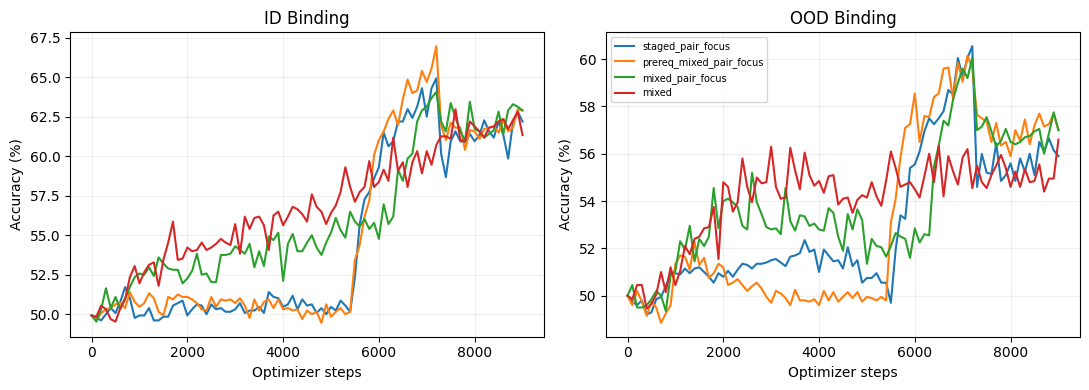

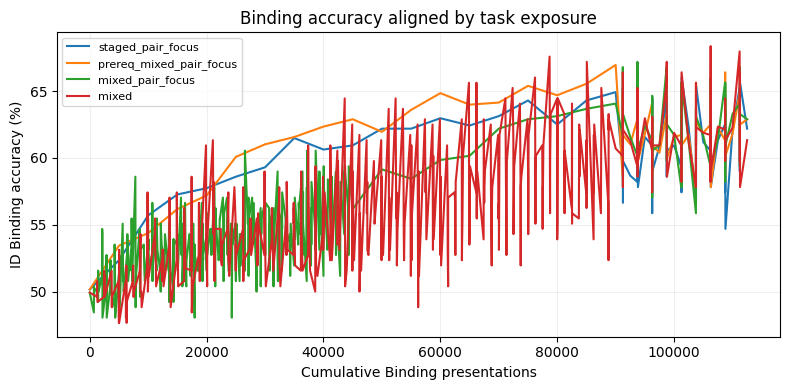

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for sch in SCHEDULES:
    sub=curves[curves.schedule==sch]
    avg=sub.groupby("step",as_index=False)[["id_pair","ood_pair"]].mean()
    axs[0].plot(avg.step,avg.id_pair,label=sch)
    axs[1].plot(avg.step,avg.ood_pair,label=sch)
for ax,title in zip(axs,("ID Binding", "OOD Binding")):
    ax.set(xlabel="Optimizer steps",ylabel="Accuracy (%)",title=title)
    ax.grid(alpha=.2)
axs[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_CURVES,dpi=160)
plt.show()

fig,ax=plt.subplots(figsize=(8,4))
for sch in SCHEDULES:
    sub=curves[curves.schedule==sch]
    # Equal exposure values may occur at many global steps before Pair is introduced:
    # show the LAST checkpoint at each exposure count, for each seed.
    by=(sub.sort_values("step").drop_duplicates(["seed","pair_exposure"],keep="last")
        .groupby("pair_exposure",as_index=False)["id_pair"].mean())
    ax.plot(by.pair_exposure,by.id_pair,label=sch)
ax.set(xlabel="Cumulative Binding presentations",ylabel="ID Binding accuracy (%)",
       title="Binding accuracy aligned by task exposure")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_EXPOSURE,dpi=160)
plt.show()

## Prediction errors and held-out combinations

Subgroups are computed from the exact same evaluation questions as the saved traces. Report their support and confusion counts, not accuracy alone.

In [ ]:
def context(row):
    task=row["template"]
    objs=row["scene"]["objects"]
    arg=row["question"]["args"]
    target_color=arg[0] if task in ("color","conjunction","pair") else ""
    target_shape=arg[-1] if task in ("shape","conjunction","pair") else ""
    colors=[o["color"] for o in objs]
    shapes=[o["shape"] for o in objs]
    subgroup="all"
    if task=="conjunction":
        c=target_color in colors
        s=target_shape in shapes
        subgroup=("both_present" if c and s else
                  "negative_missing_color" if not c and s else
                  "negative_missing_shape" if c and not s else
                  "negative_both_missing")
    elif task=="pair":
        subgroup="positive_pair_present" if int(row["label"])==1 else "negative_hard_pair"
    return {"example_id":str(row["id"]),"task":task,
            "target_color":target_color,"target_shape":target_shape,
            "pair":target_color+"-"+target_shape if task=="pair" else "",
            "n_objects":len(objs),"repeated_color":len(set(colors))<len(colors),
            "repeated_shape":len(set(shapes))<len(shapes),"subgroup":subgroup}

metadata={}
for split in ("id_dev","ood_dev"):
    path=DATA_DIR/f"{split}.jsonl"
    with path.open(encoding="utf-8") as f:
        rows=[json.loads(line) for line in f if line.strip()]
    frame=pd.DataFrame([context(row) for row in rows])
    assert frame.example_id.is_unique
    metadata[split]=frame.set_index("example_id")

def metrics(part):
    y=part.label.to_numpy()
    p=part.predicted.to_numpy()
    tp=int(((y==1)&(p==1)).sum())
    fn=int(((y==1)&(p==0)).sum())
    tn=int(((y==0)&(p==0)).sum())
    fp=int(((y==0)&(p==1)).sum())
    return {"n":len(part),"tp":tp,"fn":fn,"tn":tn,"fp":fp,
            "accuracy":(tp+tn)/len(part) if len(part) else float("nan"),
            "tpr":tp/(tp+fn) if tp+fn else float("nan"),
            "tnr":tn/(tn+fp) if tn+fp else float("nan")}

subgroups=[]
for (seed,schedule),t in traces.items():
    for split,block in t["splits"].items():
        last=np.flatnonzero(block["steps"]==9000)
        assert len(last)==1
        j=int(last[0])
        frame=pd.DataFrame({"example_id":block["ids"],
            "label":block["labels"],"predicted":block["predictions"][j]})
        frame=frame.join(metadata[split],on="example_id",validate="one_to_one")
        assert frame.task.notna().all()
        fields={"task":"task","target_shape":"target_shape",
                "target_color":"target_color","pair":"pair", "n_objects":"n_objects",
                "repeated_color":"repeated_color","repeated_shape":"repeated_shape",
                "subgroup":"subgroup"}
        for name,col in fields.items():
            for value,part in frame.groupby(col,dropna=False):
                if name in ("pair", "target_shape", "target_color"):
                    part=part[part[col]!=""]
                if part.empty:continue
                subgroups.append({"seed":seed,"schedule":schedule,"split":split,
                                  "group_type":name,"group":value,**metrics(part)})
subgroup_df=pd.DataFrame(subgroups)
subgroup_df.to_csv(SUBGROUP_CSV,index=False)
display(subgroup_df[(subgroup_df.split=="ood_dev") &
                    (subgroup_df.group_type=="pair")].groupby(
                    ["schedule","group"])[["n","tp","fn","tn","fp"]].sum())

n   tp   fn   tn   fp
schedule                group                                   
mixed                   blue-square      485  207   33   93  152
                        green-circle     545  220   55  130  140
                        purple-triangle  555  188   92   96  179
                        red-crescent     415  157   48   41  169
mixed_pair_focus        blue-square      485  183   57  118  127
                        green-circle     545  214   61  136  134
                        purple-triangle  555  213   67   76  199
                        red-crescent     415  147   58   53  157
prereq_mixed_pair_focus blue-square      485  191   49  100  145
                        green-circle     545  214   61  137  133
                        purple-triangle  555  149  131  139  136
                        red-crescent     415  110   95  100  110
staged_pair_focus       blue-square      485  155   85  128  117
                        green-circle     545  243   32   85  185
                        purple-triangle  555  114  166  176   99
                        red-crescent     415   85  120  132   78

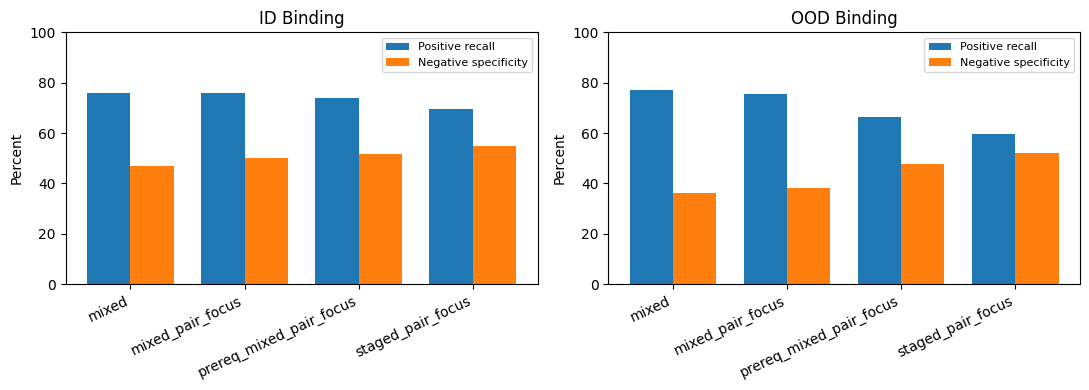

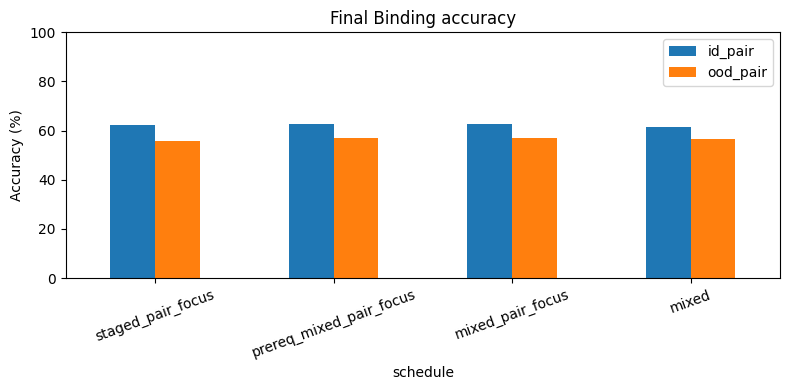

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for i,split in enumerate(("id", "ood")):
    x=final.groupby("schedule")[[f"{split}_tpr", f"{split}_tnr"]].mean()
    xpos=np.arange(len(x))
    width=0.38
    axs[i].bar(xpos-width/2,x.iloc[:,0],width,label="Positive recall")
    axs[i].bar(xpos+width/2,x.iloc[:,1],width,label="Negative specificity")
    axs[i].set_xticks(xpos,x.index,rotation=25,ha="right")
    axs[i].set(ylabel="Percent",title=f"{split.upper()} Binding",ylim=(0,100))
    axs[i].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_CLASS,dpi=160)
plt.show()
fig,ax=plt.subplots(figsize=(8,4))
means=final.groupby("schedule")[["id_pair","ood_pair"]].mean().loc[list(SCHEDULES)]
means.plot(kind="bar",ax=ax,rot=20)
ax.set(ylabel="Accuracy (%)",title="Final Binding accuracy",ylim=(0,100))
fig.tight_layout()
fig.savefig(FIGURE_FINAL,dpi=160)
plt.show()

## Forgetting and recovery across actual phase transitions

Compare the same question IDs at each transition boundary, 100 updates afterward, and at the final checkpoint. Distinguish prior-task retention from changes in Binding before it has been introduced.

In [ ]:
change_rows,example_rows=[],[]
for r in runs:
    seed,schedule=r["seed"],r["schedule"]
    t=traces[(seed,schedule)]
    for event in r["transitions"][:-1]:
        before=int(event["end_step"])
        after=before+100
        if after>=9000:continue
        for split,block in t["splits"].items():
            change=compare_three(block,before,after,9000)
            summary=summarize_changes(change)
            for _,s in summary.iterrows():
                change_rows.append({"seed":seed,"schedule":schedule,
                                    "from_phase":event["phase"],"split":split,
                                    "before_step":before,"after_step":after,**s.to_dict()})
            change["seed"]=seed
            change["schedule"]=schedule
            change["split"]=split
            change["transition_from"]=event["phase"]
            example_rows.append(change)
changes=pd.DataFrame(change_rows)
changes.to_csv(CHANGES_CSV,index=False)
examples=pd.concat(example_rows,ignore_index=True)
examples.to_csv(EXAMPLE_CHANGES_CSV,index=False,compression="gzip")
display(changes[(changes.split=="id_dev") & (changes.task!="all")][
    ["seed","schedule","from_phase","task","forgotten","newly_learned",
     "recovered","correctness_churn"]].head(32).round(3))

,seed,schedule,from_phase,task,forgotten,newly_learned,recovered,correctness_churn
1,42,mixed,mixed,color,1,1,0,0.008
2,42,mixed,mixed,conjunction,1,5,1,0.023
3,42,mixed,mixed,pair,12,7,7,0.074
4,42,mixed,mixed,shape,4,6,1,0.039
8,42,mixed_pair_focus,mixed_prefix,color,2,0,1,0.008
9,42,mixed_pair_focus,mixed_prefix,conjunction,14,9,12,0.090
10,42,mixed_pair_focus,mixed_prefix,pair,19,26,12,0.176
11,42,mixed_pair_focus,mixed_prefix,shape,33,19,27,0.203
15,42,mixed_pair_focus,pair_focus,color,0,12,0,0.047
16,42,mixed_pair_focus,pair_focus,conjunction,17,36,1,0.207
